# Load Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage

# Import Dataset

In [2]:
data = pd.read_excel('Data/GSE245759_normalized_counts.txt/GSE245759_normalized_counts.xlsx')

# Data Cleaning and EDA

Remove the samples I am not interested in keeping

In [3]:
data = data.drop(columns = ['CT+Pp-1','CT+Pp-2', 'CT+Pp-3', 'S+Pp-1', 'S+Pp-2', 'S+Pp-3',
                         'HS+Pp-1','HS+Pp-2', 'HS+Pp-3', 'S+HS+Pp-1', 'S+HS+Pp-2', 'S+HS+Pp-3' ])

To make the dataframe easier to work with, I need to change the gene names from a column to the index. That way the only values in my dataframe are numbers

In [4]:
data = data.set_index('genes')

Filter the dataset for low-expression genes. Only keep the genes with counts >= 10 in 25% of samples. 

In [5]:
print("Number of samples before filtering: ", data.shape[0])

#check which samples have expression >= 10
expressed = data >= 10

#how many samples in each gene meet the count threshold
expressed_samples = expressed.sum(axis=1)

#filter the data to only keep the samples where threshold is met in 
#25% of samples
data = data[expressed_samples >= 3]

print("Number of samples after filtering: ", data.shape[0])

Number of samples before filtering:  34075
Number of samples after filtering:  20390


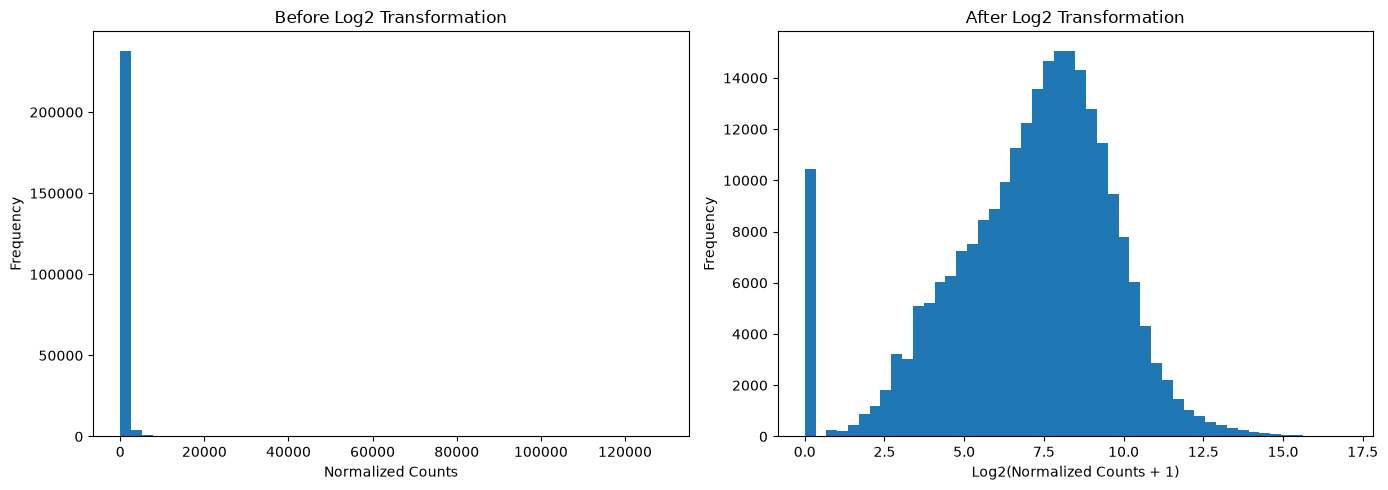

In [6]:
# Log2 transform normalized counts
data_log = np.log2(data + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Histogram BEFORE log transformation
axes[0].hist(data.values.flatten(), bins=50)
axes[0].set_title('Before Log2 Transformation')
axes[0].set_xlabel('Normalized Counts')
axes[0].set_ylabel('Frequency')

# Histogram AFTER log transformation
axes[1].hist(data_log.values.flatten(), bins=50)
axes[1].set_title('After Log2 Transformation')
axes[1].set_xlabel('Log2(Normalized Counts + 1)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()

plt.savefig('images/data_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Model Building / Model Training

## PCA

In [7]:
# I need to transpose the dataset so the samples are rows and genes are the columns
X = data_log.T

pca = PCA(n_components = 2)

X_pca = pca.fit_transform(X)



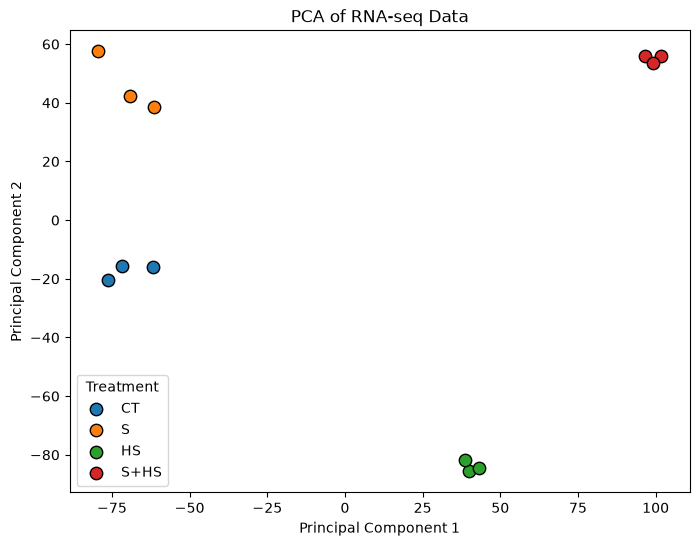

In [8]:
group_names = ['CT', 'S', 'HS', 'S+HS']

sample_to_group = {'CT-1':'CT', 'CT-2':'CT', 'CT-3':'CT', 'S-1':'S',
    'S-2': 'S', 'S-3':'S', 'HS-1':'HS', 'HS-2':'HS', 'HS-3':'HS', 
    'S+HS-1': 'S+HS', 'S+HS-2':'S+HS', 'S+HS-3':'S+HS'}

plt.figure(figsize=(8, 6))

for group in ['CT', 'S', 'HS', 'S+HS']:
    samples = [i for i, s in enumerate(X.index)
               if sample_to_group[s] == group]

    plt.scatter(X_pca[samples, 0], X_pca[samples, 1],
                label=group, edgecolor='k', s=80)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of RNA-seq Data")
plt.legend(title="Treatment")
plt.savefig('images/initial_pca.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
print("Explained variance:", pca.explained_variance_ratio_)

Explained variance: [0.2930858  0.17257347]


## Heatmap

C:\Users\carol\OneDrive\Desktop\CSPB\CSPB_4622\Mini Project 2\my-env\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\carol\OneDrive\Desktop\CSPB\CSPB_4622\Mini Project 2\my-env\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


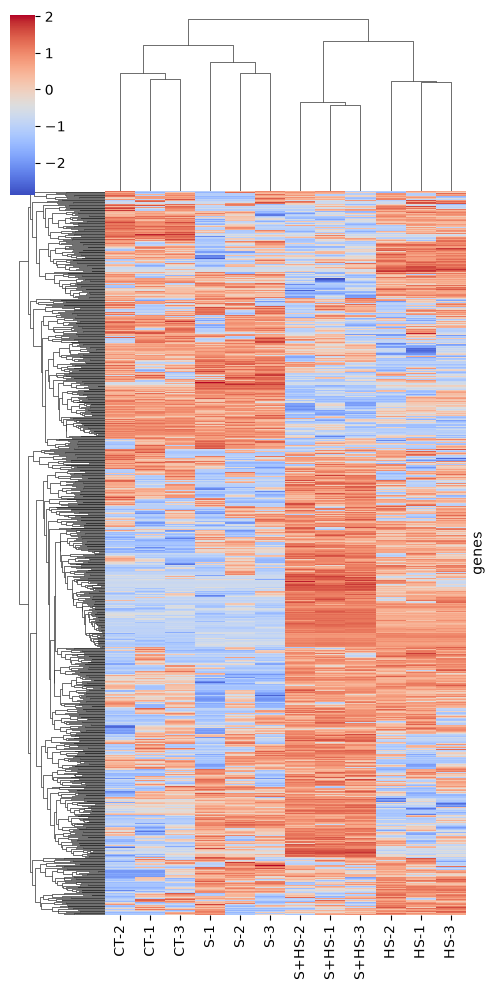

In [10]:
#select top 500 most variable genes
top_genes = X.var().nlargest(1000).index

#zscore = 0 will standardize the gene across each sample for each gene
#transposed the heatmap data so it looks more like a normal heatmap
sns.clustermap(X[top_genes].T, cmap='coolwarm', z_score=0, figsize= (5,10), yticklabels=False)
plt.savefig('images/initial_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()